<a href="https://colab.research.google.com/github/mardocheeogecime-gif/Rede_Colabora-o_Acad-mica_ECI_UFMG/blob/main/QHE_CAPES_2013_2024_LAB_UNICO_REVISAO_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quality in Higher Education — Integrated final analytical revision (CAPES 2013–2024)

Source of truth: the **V2 official census** frozen in Drive, previously built from the 12 CAPES/Sucupira annual CSV datasets and linked to the identified theses/dissertations (BTD) subset. This notebook creates **new outputs** in `70_QHE_FINAL_REVIEW_2013_2024`, never overwriting V2.

**Scientific guardrails:** (1) registered grades are not annual evaluations; (2) doctoral provision is a *necessary-condition proxy*, not proof of full eligibility for grades 6–7; (3) unmatched BTD programme-years are *unobserved*, not verified zero production; (4) counts refer to identified theses/dissertations, never all scholarly output; (5) no causal claims, no artificial odds ratios for structural zeros; (6) non-probability administrative census—intervals describe models rather than sampling error; (7) English tables and figures printed directly in Colab.

**Tasks:** complete census, eligible-denominator sensitivity, lifecycle and observed update patterns, Kitagawa decomposition, zero-coverage sensitivity, Theil and Gini decompositions, Lorenz curves, retained/excluded profiles, cluster-robust associative models, data-flow diagram, audited data dictionary and end-to-end manifest.


In [1]:
# CELL 1/4 — CPU | FROZEN INPUT CONTRACT, VALIDATION, DERIVED COHORTS
%pip -q install pandas numpy pyarrow scipy statsmodels matplotlib openpyxl
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, re, unicodedata, warnings, sys, platform
import numpy as np, pandas as pd
from IPython.display import display, Markdown
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
ROOT=Path('/content/drive/MyDrive/CAPES_Epistemic_Change')
V2=ROOT/'69_HEQ_ESTRATIFICACAO_INSTITUCIONAL_CENSO_V2_SEPARACAO_CORRIGIDA'
OUT=ROOT/'70_QHE_FINAL_REVIEW_2013_2024'; OUT.mkdir(parents=True,exist_ok=True)
FIG=OUT/'FIGURES_EN'; FIG.mkdir(exist_ok=True)
TAB=OUT/'TABLES_EN'; TAB.mkdir(exist_ok=True)
SUP=OUT/'SUPPLEMENT_EN'; SUP.mkdir(exist_ok=True)
SOURCES={
 'census':V2/'01_OFFICIAL_PPG_YEAR_CENSUS.parquet',
 'source_integrity':V2/'01_source_integrity_by_year.csv',
 'v2_model_diagnostics':V2/'02_glm_fit_diagnostics.csv',
 'v2_model_estimates':V2/'02_glm_adjusted_associations.csv',
 'v2_grade_transitions':V2/'02_concept_registry_transition_by_year.csv',
 'v2_area_overlap':V2/'02_academic_area_overlap_audit.csv'
}
for k,p in SOURCES.items():
    if not p.is_file(): raise FileNotFoundError(f'Missing frozen V2 artifact {k}: {p}')
def file_sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for ch in iter(lambda:f.read(4*1024*1024),b''): h.update(ch)
    return h.hexdigest()
def clean_upper(v):
    if pd.isna(v):return ''
    v=unicodedata.normalize('NFKD',str(v)).encode('ascii','ignore').decode().upper().strip()
    return re.sub(r'\s+',' ',v)
def has_doctorate(value):
    t=clean_upper(value)
    if t in ('','NAN','NONE','NA','NAO INFORMADO','-'):return pd.NA
    # An explicit doctorate token is interpreted as an observed degree offering.
    if re.search(r'\b(DOUTORADO|DOUTOR|DOCTORATE|PHD)\b',t):return True
    if re.search(r'\b(MESTRADO|MESTRE|MASTER)\b',t):return False
    return pd.NA
c=pd.read_parquet(SOURCES['census']).copy()
needed=['ppg','year','grade','degree','modality','administration','area_group',
        'n_docs','has_btd_record','grade_numeric','valid_grade_3to7','high_grade_6_7']
missing=sorted(set(needed)-set(c.columns))
if missing: raise AssertionError(f'Missing V2 census columns: {missing}; actual columns: {list(c.columns)}')
c['ppg']=c.ppg.astype('string').str.strip();c['year']=pd.to_numeric(c.year,errors='raise').astype(int)
assert not c[['ppg','year']].isna().any().any() and not c.duplicated(['ppg','year']).any()
assert len(c)==51901 and c.year.between(2013,2024).all()
c['n_docs']=pd.to_numeric(c.n_docs,errors='raise').astype('int64')
c['has_btd_record']=c.has_btd_record.astype(bool)
assert c.n_docs.ge(0).all() and c.n_docs.sum()==993086
assert int(c.has_btd_record.sum())==48355
assert (c.loc[c.has_btd_record,'n_docs']>0).all()
assert (c.loc[~c.has_btd_record,'n_docs']==0).all()
c['grade_label']=c.grade.astype('string').str.strip().str.upper()
c['grade_is_A']=c.grade_label.eq('A').fillna(False)
c['grade_high']=c.grade_label.isin(['6','7'])
c['grade_valid_numeric']=c.grade_label.isin(['3','4','5','6','7'])
c['doctoral_observed']=pd.Series(c.degree.map(has_doctorate),index=c.index,dtype='boolean')
c['degree_raw']=c.degree.astype('string').fillna('MISSING').str.strip()
c['sector']=c.administration.map(clean_upper).map({'PUBLICA':'Public','PRIVADA':'Private'}).fillna('Unknown')
c['programme_modality']=c.modality.map(clean_upper).map({'ACADEMICO':'Academic','PROFISSIONAL':'Professional'}).fillna('Unknown')
c['area']=c.area_group.astype('string').fillna('UNKNOWN_AREA')
c['is_public']=c.sector.eq('Public')
c['is_academic']=c.programme_modality.eq('Academic')
c['start_year']=pd.to_numeric(c.get('programme_start_year',pd.Series(np.nan,index=c.index)),errors='coerce')
# V2 did not retain AN_INICIO_PROGRAMA; retrieve start year only from frozen OFFICIAL annual files below, without re-downloading.
sel_path=ROOT/'58_LAB01_HEQ_2013_2024_V21_CONSOLIDACAO_OFICIAL'/'01_selected_official_resources.csv'
start_read=[]
if sel_path.exists():
    sel=pd.read_csv(sel_path,dtype='string')
    if {'year_hint','local_path','sha256'}.issubset(sel.columns):
        for r in sel.itertuples(index=False):
            fp=Path(str(r.local_path))
            if not fp.exists() or file_sha(fp)!=str(r.sha256):raise AssertionError(f'Annual official hash/path changed: {fp}')
            dd=None
            for enc in ['utf-8-sig','latin1']:
                for sep in [';',',']:
                    try:
                        tmp=pd.read_csv(fp,sep=sep,encoding=enc,dtype='string',low_memory=False)
                        if {'CD_PROGRAMA_IES','AN_BASE'}.issubset(tmp.columns):dd=tmp;break
                    except Exception:pass
                if dd is not None:break
            if dd is None:raise RuntimeError(f'Could not inspect official annual CSV: {fp}')
            s_cols=[z for z in ['AN_INICIO_PROGRAMA','ANO_INICIO_PROGRAMA'] if z in dd.columns]
            block=dd[['CD_PROGRAMA_IES','AN_BASE']+s_cols].copy()
            block.columns=['ppg','year']+s_cols
            block['ppg']=block.ppg.str.strip();block['year']=pd.to_numeric(block.year,errors='raise').astype(int)
            if s_cols:
                series=[pd.to_numeric(block[z],errors='coerce') for z in s_cols]
                block['start_year']=series[0]
                for sr in series[1:]:block['start_year']=block.start_year.fillna(sr)
            else:block['start_year']=np.nan
            start_read.append(block[['ppg','year','start_year']])
if start_read:
    start=pd.concat(start_read,ignore_index=True)
    tests=start.groupby(['ppg','year']).start_year.nunique(dropna=True)
    if (tests>1).any():raise AssertionError('Conflicting original programme start dates; do not overwrite')
    start=start.drop_duplicates(['ppg','year'])
    c=c.drop(columns='start_year').merge(start,on=['ppg','year'],how='left',validate='one_to_one')
    assert len(c)==51901
c['age_observed']=c.year-c.start_year
c.loc[~c.age_observed.between(0,150),'age_observed']=np.nan
c['age_band']=pd.cut(c.age_observed,bins=[-1,4,9,19,39,150],labels=['0–4','5–9','10–19','20–39','40+']).astype('string').fillna('Age unknown')
# These are observational reference-year cohorts, NOT evaluation-event dates.
c['period_group']=pd.cut(c.year,[2012,2016,2020,2024],labels=['2013–2016','2017–2020','2021–2024']).astype('string')
c['eligible_proxy']=c.doctoral_observed.fillna(False)&c.grade_valid_numeric
c['eligible_proxy_wA']=c.doctoral_observed.fillna(False)&(c.grade_valid_numeric|c.grade_is_A)
c['grade_6_7_or_A_as_5']=c.grade_high # A is never counted as a high grade
# 6–7 eligibility requires additional evidence (evaluation-cycle, doctoral age, ratings) unavailable here.
audit={'n_ppg_year':len(c),'n_document_total':int(c.n_docs.sum()),
 'n_btd_observed':int(c.has_btd_record.sum()),
 'degree_categories':c.degree_raw.value_counts(dropna=False).to_dict(),
 'doctorate_proxy_true':int(c.doctoral_observed.eq(True).sum()),
 'doctorate_proxy_false':int(c.doctoral_observed.eq(False).sum()),
 'doctorate_proxy_unknown':int(c.doctoral_observed.isna().sum()),
 'high_grade_without_doctorate_proxy':int((c.grade_high & c.doctoral_observed.eq(False).fillna(False)).sum()),
 'missing_age':int(c.age_observed.isna().sum())}
(OUT/'01_input_audit.json').write_text(json.dumps(audit,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
c.to_parquet(OUT/'01_CENSUS_WITH_ELIGIBILITY_PROXY.parquet',index=False)
print('FINAL REVIEW | OFFICIAL PPG-years',len(c),'| BTD observed',int(c.has_btd_record.sum()),'| identified documents',int(c.n_docs.sum()))
print('Doctorate-offering proxy coverage:');display(pd.DataFrame([audit]).drop(columns=['degree_categories']))
print('Original degree labels (never silently recoded):');display(c.degree_raw.value_counts().rename_axis('Original degree field').reset_index(name='PPG-years'))
print('Source V2 retained; all revised outputs:',OUT)


Mounted at /content/drive
FINAL REVIEW | OFFICIAL PPG-years 51901 | BTD observed 48355 | identified documents 993086
Doctorate-offering proxy coverage:


,n_ppg_year,n_document_total,n_btd_observed,doctorate_proxy_true,doctorate_proxy_false,doctorate_proxy_unknown,high_grade_without_doctorate_proxy,missing_age
0,51901,993086,48355,28251,23650,0,0,0


Original degree labels (never silently recoded):


,Original degree field,PPG-years
0,MESTRADO/DOUTORADO,27017
1,MESTRADO,14991
2,MESTRADO PROFISSIONAL,8659
3,DOUTORADO,895
4,MESTRADO PROFISSIONAL/DOUTORADO PROFISSIONAL,322
5,DOUTORADO PROFISSIONAL,17


Source V2 retained; all revised outputs: /content/drive/MyDrive/CAPES_Epistemic_Change/70_QHE_FINAL_REVIEW_2013_2024


In [2]:
# CELL 2/4 — CPU | ELIGIBILITY, GRADE-A SENSITIVITY, TIMING, DECOMPOSITION
from scipy.stats import entropy
from statsmodels.stats.proportion import proportion_confint
T={}
def save_table(name,df):
    T[name]=df.copy()
    df.to_csv(TAB/f'{name}.csv',index=False,encoding='utf-8-sig')
    print(f'{name}: {len(df):,} rows')
def proportions(g):
    n=int(len(g));h=int(g.grade_high.sum());vn=int(g.grade_valid_numeric.sum())
    p=int(g.eligible_proxy.sum()); pe=int((g.grade_high & g.eligible_proxy).sum())
    a=int(g.grade_is_A.sum());pa=int(g.eligible_proxy_wA.sum())
    return pd.Series({'Registered programmes':n,'Numeric grades 3–7':vn,
      'Grades 6–7':h,'Share, numeric grades 3–7':h/vn if vn else np.nan,
      'Doctorate-offering proxy (numeric grades)':p,
      'Grades 6–7 among doctoral proxy':pe,
      'Share, doctorate-offering proxy':pe/p if p else np.nan,
      'Grade A':a,'Proxy denominator including A-as-5':pa,
      'Share, proxy plus A-as-5':pe/pa if pa else np.nan,
      'Proxy coverage of all registered':p/n if n else np.nan,
      'Doctoral offering unknown':int(g.doctoral_observed.isna().sum()),
      'BTD documents identified':int(g.n_docs.sum())})
for name,keys in [
 ('Table_1_Annual_Eligibility',['year']),
 ('Table_2_Eligibility_By_Sector',['year','sector']),
 ('Table_3_Eligibility_By_Modality',['year','programme_modality']),
 ('Supplement_S1_Eligibility_By_Degree',['year','degree_raw']),
 ('Supplement_S2_A_Grade_By_Area',['year','area'])]:
    df=c.groupby(keys,observed=True,dropna=False).apply(proportions,include_groups=False).reset_index()
    save_table(name,df)
# CRITICAL: flag potential anomalies for manual investigation, never silently drop or recode them.
anomalies=c.loc[c.grade_high & c.doctoral_observed.ne(True).fillna(True),
  ['ppg','year','grade','degree_raw','programme_modality','sector','area']].copy()
save_table('QA_Grade_6_7_Without_Confirmed_Doctoral_Proxy',anomalies)
# 2013–16 / 2017–20 / 2021–24 are REPORTING PERIODS, not proven evaluation-result dates.
periods=c.groupby(['period_group','year'],observed=True).apply(proportions,include_groups=False).reset_index()
save_table('Table_4_Registered_Grade_Reporting_Periods',periods)
# Stable programme-year linked comparisons, do not interpret as independent annual assessments.
g=c[['ppg','year','grade_label','area','sector','programme_modality','doctoral_observed']].sort_values(['ppg','year']).copy()
g['prev_year']=g.groupby('ppg').year.shift();g['prev_grade']=g.groupby('ppg').grade_label.shift()
g=g[g.year.eq(g.prev_year+1)].copy()
g['grade_changed']=g.grade_label.ne(g.prev_grade).fillna(False)
changes=g.groupby('year').agg(Programme_pairs=('ppg','size'),Changed_registered_grade=('grade_changed','sum')).reset_index()
changes['Share_changed']=changes.Changed_registered_grade/changes.Programme_pairs
save_table('Supplement_S3_Registry_Grade_Change_Audit',changes)
# Exact Kitagawa symmetric decomposition of change in high-grade prevalence by area, with categories 3–7.
def kitagawa(df,y0,y1,stratum):
    d0=df[(df.year==y0)&df.grade_valid_numeric&df[stratum].notna()]
    d1=df[(df.year==y1)&df.grade_valid_numeric&df[stratum].notna()]
    o=[]
    for y,dd in [(y0,d0),(y1,d1)]:
        zz=dd.groupby(stratum,observed=True).agg(n=('ppg','size'),h=('grade_high','sum')).reset_index()
        zz['year']=y;o.append(zz)
    z=pd.concat(o).pivot(index=stratum,columns='year',values=['n','h']).fillna(0)
    total0=float(z['n'][y0].sum());total1=float(z['n'][y1].sum())
    z0=z['n'][y0].to_numpy(dtype=float);z1=z['n'][y1].to_numpy(dtype=float)
    h0=z['h'][y0].to_numpy(dtype=float);h1=z['h'][y1].to_numpy(dtype=float)
    p0=z0/total0;p1=z1/total1
    r0=np.divide(h0,z0,out=np.full_like(h0,np.nan),where=z0>0)
    r1=np.divide(h1,z1,out=np.full_like(h1,np.nan),where=z1>0)
    # Entering/exiting strata have no observed within-stratum rate in one year;
    # transparent common-strata decomposition and an EXACT entry/exit residual.
    both=(z0>0)&(z1>0)
    comp=np.zeros(len(z0));within=np.zeros(len(z0))
    comp[both]=(p1[both]-p0[both])*(r1[both]+r0[both])/2
    within[both]=(r1[both]-r0[both])*(p1[both]+p0[both])/2
    aggregate0=h0.sum()/total0;aggregate1=h1.sum()/total1
    residual=(aggregate1-aggregate0)-(comp.sum()+within.sum())
    return {'comparison':f'{y0}–{y1}','stratification':stratum,
       'ppg_year_y0':int(total0),'ppg_year_y1':int(total1),
       'share_y0':aggregate0,'share_y1':aggregate1,'delta_share':aggregate1-aggregate0,
       'composition_common':float(comp.sum()),'within_common':float(within.sum()),
       'entry_exit_residual':float(residual), 'n_common_strata':int(both.sum()),
       'n_only_y0':int(((z0>0)&(z1==0)).sum()),'n_only_y1':int(((z1>0)&(z0==0)).sum()),
       'sum_components':float(comp.sum()+within.sum()+residual)}
decomp=[]
for a,b in [(2013,2016),(2016,2017),(2017,2020),(2020,2021),(2021,2024),(2013,2024)]:
    for k in ['area','sector','programme_modality']:
        decomp.append(kitagawa(c,a,b,k))
D=pd.DataFrame(decomp)
assert np.allclose(D.delta_share,D.sum_components,rtol=0,atol=1e-12)
save_table('Table_5_Kitagawa_Grade_Decomposition',D)
print('GRADE ELIGIBILITY BY REFERENCE YEAR (both denominators):')
display(T['Table_1_Annual_Eligibility'])
print('REPORTING-UPDATE COUNTS (not evaluation event dates):');display(changes)
print('DECOMPOSITION:');display(D)


Table_1_Annual_Eligibility: 12 rows
Table_2_Eligibility_By_Sector: 24 rows
Table_3_Eligibility_By_Modality: 24 rows
Supplement_S1_Eligibility_By_Degree: 63 rows
Supplement_S2_A_Grade_By_Area: 589 rows
QA_Grade_6_7_Without_Confirmed_Doctoral_Proxy: 0 rows
Table_4_Registered_Grade_Reporting_Periods: 12 rows
Supplement_S3_Registry_Grade_Change_Audit: 11 rows
Table_5_Kitagawa_Grade_Decomposition: 18 rows
GRADE ELIGIBILITY BY REFERENCE YEAR (both denominators):


,year,Registered programmes,Numeric grades 3–7,Grades 6–7,"Share, numeric grades 3–7",Doctorate-offering proxy (numeric grades),Grades 6–7 among doctoral proxy,"Share, doctorate-offering proxy",Grade A,Proxy denominator including A-as-5,"Share, proxy plus A-as-5",Proxy coverage of all registered,Doctoral offering unknown,BTD documents identified
0,2013,3568.0,3537.0,415.0,0.117331,2100.0,415.0,0.197619,0.0,2100.0,0.197619,0.588565,0.0,67431.0
1,2014,3765.0,3748.0,415.0,0.110726,2119.0,415.0,0.195847,0.0,2119.0,0.195847,0.562815,0.0,70487.0
2,2015,3946.0,3931.0,415.0,0.105571,2151.0,415.0,0.192934,0.0,2151.0,0.192934,0.545109,0.0,75666.0
3,2016,4186.0,4177.0,415.0,0.099354,2182.0,415.0,0.190192,0.0,2182.0,0.190192,0.521261,0.0,80075.0
4,2017,4347.0,4299.0,498.0,0.115841,2224.0,498.0,0.223921,0.0,2224.0,0.223921,0.511617,0.0,85137.0
5,2018,4363.0,4298.0,492.0,0.114472,2276.0,492.0,0.216169,2.0,2276.0,0.216169,0.521659,0.0,90295.0
6,2019,4570.0,4272.0,492.0,0.115169,2416.0,492.0,0.203642,257.0,2434.0,0.202136,0.528665,0.0,94349.0
7,2020,4559.0,4223.0,491.0,0.116268,2449.0,491.0,0.200490,318.0,2476.0,0.198304,0.537179,0.0,79989.0
8,2021,4709.0,4551.0,674.0,0.148099,2521.0,674.0,0.267354,75.0,2528.0,0.266614,0.535358,0.0,82600.0
9,2022,4594.0,4476.0,673.0,0.150357,2506.0,673.0,0.268555,82.0,2512.0,0.267914,0.545494,0.0,83981.0


REPORTING-UPDATE COUNTS (not evaluation event dates):


,year,Programme_pairs,Changed_registered_grade,Share_changed
0,2014,3543,0,0.0
1,2015,3741,3,0.000802
2,2016,3931,0,0.0
3,2017,4155,1285,0.309266
4,2018,4328,88,0.020333
5,2019,4308,8,0.001857
6,2020,4494,9,0.002003
7,2021,4538,2036,0.448656
8,2022,4580,0,0.0
9,2023,4578,0,0.0


DECOMPOSITION:


,comparison,stratification,ppg_year_y0,ppg_year_y1,share_y0,share_y1,delta_share,composition_common,within_common,entry_exit_residual,n_common_strata,n_only_y0,n_only_y1,sum_components
0,2013–2016,area,3537,4177,0.117331,0.099354,-0.017977,-0.003264,-0.014713,3.469447e-18,49,0,0,-0.017977
1,2013–2016,sector,3537,4177,0.117331,0.099354,-0.017977,-0.000447,-0.017530,-6.938894e-18,2,0,0,-0.017977
2,2013–2016,programme_modality,3537,4177,0.117331,0.099354,-0.017977,-0.004089,-0.013889,0.000000e+00,2,0,0,-0.017977
3,2016–2017,area,4177,4299,0.099354,0.115841,0.016487,-0.000479,0.016966,3.469447e-18,49,0,0,0.016487
4,2016–2017,sector,4177,4299,0.099354,0.115841,0.016487,0.000076,0.016412,1.040834e-17,2,0,0,0.016487
5,2016–2017,programme_modality,4177,4299,0.099354,0.115841,0.016487,-0.000467,0.016954,2.428613e-17,2,0,0,0.016487
6,2017–2020,area,4299,4223,0.115841,0.116268,0.000427,0.000057,0.000370,-1.154675e-17,49,0,0,0.000427
7,2017–2020,sector,4299,4223,0.115841,0.116268,0.000427,0.000275,0.000152,-1.490778e-17,2,0,0,0.000427
8,2017–2020,programme_modality,4299,4223,0.115841,0.116268,0.000427,0.000031,0.000396,-3.079134e-17,2,0,0,0.000427
9,2020–2021,area,4223,4551,0.116268,0.148099,0.031831,-0.001134,0.032965,0.000000e+00,49,0,0,0.031831


In [3]:
# CELL 3/4 — CPU | BTD ROBUSTNESS, DECOMPOSABLE INEQUALITY, LORENZ, REGRESSIONS
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.special import expit

def distribution_metrics(values):
    a=np.asarray(values,dtype=np.float64);a=a[np.isfinite(a)]
    if len(a)==0:return {'n':0,'total':0,'Gini':np.nan,'Top_10pct_share':np.nan,'Theil_T':np.nan,'Theil_L':np.nan,'HHI':np.nan}
    if np.any(a<0):raise ValueError('Negative BTD observed count')
    n=len(a);total=a.sum()
    if total<=0:return {'n':n,'total':0,'Gini':np.nan,'Top_10pct_share':np.nan,'Theil_T':np.nan,'Theil_L':np.nan,'HHI':np.nan}
    ar=np.sort(a);mean=total/n
    gini=float(((2*np.arange(1,n+1)-n-1)@ar)/(n*total))
    top=float(ar[-max(1,int(np.ceil(0.1*n))):].sum()/total)
    pos=a>0
    theil=float(np.mean(np.where(pos,(a/mean)*np.log(np.maximum(a/mean,1e-300)),0)))
    # Theil L is infinite when any recorded zero is included, and is NOT regularised.
    theil_L=float(np.mean(np.log(mean/a))) if np.all(pos) else np.inf
    return {'n':n,'total':int(total),'Gini':gini,'Top_10pct_share':top,
            'Theil_T':theil,'Theil_L':theil_L,'HHI':float(((a/total)**2).sum())}
metrics=[]
for y,gg in c.groupby('year'):
    for frame,subset in [('FULL_FRAME_UNOBSERVED_AS_ZERO',gg),
                         ('MATCHED_ONLY',gg[gg.has_btd_record]),
                         ('ACADEMIC_ONLY_FULL_FRAME',gg[gg.is_academic])]:
        m=distribution_metrics(subset.n_docs)
        metrics.append({'year':int(y),'frame':frame,'n_registered':len(gg),
                        'n_in_metric':len(subset),'n_identified_BTD':int(subset.n_docs.sum()),
                        'fraction_matched':float(gg.has_btd_record.mean()),**m})
M=pd.DataFrame(metrics)
save_table('Table_6_BTD_Concentration_Bounds',M)
# A defensible descriptive sensitivity range from the two reporting frames, NOT a bound on true total production.
pivot=M[M.frame.isin(['FULL_FRAME_UNOBSERVED_AS_ZERO','MATCHED_ONLY'])].pivot(index='year',columns='frame',values=['Gini','Top_10pct_share','Theil_T'])
sens=pivot.copy();sens.columns=[f'{a}_{b}' for a,b in sens.columns];sens=sens.reset_index()
for metric in ['Gini','Top_10pct_share','Theil_T']:
    sens[f'{metric}_frame_difference']=sens[f'{metric}_FULL_FRAME_UNOBSERVED_AS_ZERO']-sens[f'{metric}_MATCHED_ONLY']
save_table('Supplement_S4_Unobserved_Zero_Sensitivity',sens)
# True Theil T decompositions over the full registry (including zero identified counts).
def theil_decompose(gg,col):
    total=gg.n_docs.sum();N=len(gg)
    if N==0 or total==0:return None
    national=distribution_metrics(gg.n_docs)['Theil_T']
    within=0.;between=0.;groups=0
    for _,sub in gg.groupby(col,dropna=False,observed=True):
        n=len(sub);sx=sub.n_docs.sum()
        if sx<=0:continue
        w=sx/total;groups+=1
        within+=w*distribution_metrics(sub.n_docs)['Theil_T']
        between+=w*np.log(w/(n/N))
    assert np.isclose(national,within+between,atol=1e-9), (national,within,between)
    return {'year':int(gg.year.iloc[0]),'grouping':col,'n_groups_with_docs':groups,
      'Theil_T_total':national,'Theil_T_within':within,'Theil_T_between':between,
      'Share_between':between/national if national>0 else np.nan,
      'n_official':N,'n_observed':int(gg.has_btd_record.sum())}
decomp_BTD=[]
for yr,gg in c.groupby('year'):
    for col in ['sector','programme_modality','area']:
        decomp_BTD.append(theil_decompose(gg,col))
TB=pd.DataFrame(decomp_BTD)
save_table('Table_7_Theil_Decomposition_By_Group',TB)
# Explicit Lorenz points for two anchor years (200 quantile points including 0 and 1)
lorenz=[]
for yr in [2013,2024]:
    for frame,gg in [('FULL_FRAME_UNOBSERVED_AS_ZERO',c[c.year.eq(yr)]),
                     ('MATCHED_ONLY',c[c.year.eq(yr)&c.has_btd_record])]:
        x=np.sort(gg.n_docs.to_numpy(dtype=np.float64)); cum=np.r_[0.,np.cumsum(x)];cum=cum/cum[-1]
        positions=np.linspace(0,1,201)
        for p in positions:
            loc=p*len(x);i=int(np.floor(loc));i=min(i,len(x));frac=loc-i
            share=float(cum[i] if i==len(x) else (1-frac)*cum[i]+frac*cum[i+1])
            lorenz.append({'year':yr,'frame':frame,'Programme_population_share':p,'BTD_output_share':share})
L=pd.DataFrame(lorenz);save_table('Figure_Data_Lorenz_2013_2024',L)
# Empirical linkage coverage by year, sector, modality, area. Exact linkage match != completeness.
cov=[]
for keys in [['year'],['year','sector'],['year','programme_modality'],['year','area']]:
    z=c.groupby(keys,dropna=False,observed=True).agg(n_official=('ppg','size'),n_btd=('has_btd_record','sum'),docs=('n_docs','sum')).reset_index()
    z['coverage_pct']=100*z.n_btd/z.n_official;z['strata']=' + '.join(keys);cov.append(z)
coverage=pd.concat(cov,ignore_index=True);save_table('Supplement_S5_BTD_Observed_Coverage',coverage)
# Programmes included/excluded in STRICT V2 AREA-overlap model; no random selection inference.
support=pd.read_csv(SOURCES['v2_area_overlap'],dtype={'area_group':'string'})
selection=[];model_outputs=[]
for yr in [2016,2020,2024]:
    subset=c[c.year.eq(yr)&c.grade_valid_numeric&c.is_academic&c.sector.isin(['Public','Private'])].copy()
    su=support[(support.year==yr)&support.supported_all_2x2_cells_positive.astype(str).str.lower().eq('true')]
    kept=set(su.area_group.astype(str).str.strip())
    subset['retained']=subset.area.astype(str).isin(kept)
    # V2 strict re-estimation contractual count
    diag=pd.read_csv(SOURCES['v2_model_diagnostics'])
    ref=diag[diag.year.eq(yr)]
    assert len(ref)==1 and int(subset.retained.sum())==int(ref.n_model.iloc[0]),f'Mismatch V2 selection {yr}'
    subset['volume_band']=pd.cut(subset.n_docs,[-1,0,9,19,39,10**10],labels=['0 identified','1–9','10–19','20–39','40+'])
    for var in ['sector','programme_modality','area','degree_raw','age_band','volume_band']:
        table=subset.groupby([var,'retained'],observed=True,dropna=False).agg(n=('ppg','size'),high=('grade_high','sum')).reset_index()
        table['year']=yr;table['dimension']=var;table=table.rename(columns={var:'category'})
        selection.append(table)
    # Defensible cluster-robust inference: cluster by institution ID where present; otherwise do not replace with false IDs.
    x=subset[subset.retained].copy()
    x['high']=x.grade_high.astype(int);x['public']=x.is_public.astype(int)
    assert x.groupby('sector').high.sum().gt(0).all()
    # Cluster labels from unambiguous official CAPES institution code, fallback to ppg only as a labelled sensitivity.
    institution_code=x.ies_capes.astype('string') if 'ies_capes' in x else pd.Series(pd.NA,index=x.index,dtype='string')
    institution_ok=institution_code.notna().all() and institution_code.nunique()>25
    group=institution_code.astype(str) if institution_ok else x.ppg.astype(str)
    fit=smf.glm('high ~ public + C(area)',data=x,family=sm.families.Binomial()).fit(cov_type='cluster',cov_kwds={'groups':group},maxiter=160)
    b=float(fit.params['public']); se=float(fit.bse['public'])
    if not (fit.converged and np.isfinite([b,se]).all() and abs(b)<8 and se>0):
        raise RuntimeError(f'Cannot identify stable cluster-robust model {yr}')
    y=x.high.to_numpy(dtype=float); phat=fit.predict(x)
    brier=float(np.mean((y-phat)**2))
    model_outputs.append({'year':yr,'n_initial':len(subset),'n_retained':len(x),'fraction_retained':len(x)/len(subset),
      'n_areas':x.area.nunique(),'cluster_unit':'CAPES institution code' if institution_ok else 'PPG (fallback)',
      'n_clusters':group.nunique(),'log_OR_public':b,'cluster_SE':se,
      'OR_public_vs_private':np.exp(b),'CI95_low':np.exp(b-1.96*se),'CI95_high':np.exp(b+1.96*se),
      'p_value_model':float(fit.pvalues['public']),'deviance':float(fit.deviance),
      'Brier_score_descriptive':brier,'model_scope':'Academic programmes; V2 strict common area support'})
SS=pd.concat(selection,ignore_index=True);save_table('Table_8_Retained_Excluded_Profiles',SS)
REG=pd.DataFrame(model_outputs);save_table('Table_9_Institution_Cluster_Robust_Models',REG)
# Threshold sensitivity: comparison within doctorate-offering proxy, academic only; support condition audited.
threshold=[]
for yr in [2016,2020,2024]:
    zz=c[c.year.eq(yr)&c.is_academic&c.doctoral_observed.eq(True).fillna(False)&c.grade_valid_numeric]
    for cond,label in [(zz.grade_label.isin(['5','6','7']),'Grades ≥5'),(zz.grade_high,'Grades 6–7')]:
        for sector,sub in zz.groupby('sector'):
            if sector not in ['Public','Private']:continue
            hits=int(cond.loc[sub.index].sum())
            threshold.append({'year':yr,'threshold':label,'sector':sector,'n_doctoral_academic':len(sub),
                 'n_threshold':hits,'share':hits/len(sub) if len(sub) else np.nan})
save_table('Supplement_S6_Threshold_Sensitivity',pd.DataFrame(threshold))
print('REGRESSION (institution-clustered; associational):');display(REG)
print('CONCENTRATION sensitivity:');display(M[M.frame.isin(['FULL_FRAME_UNOBSERVED_AS_ZERO','MATCHED_ONLY'])])
print('Theil decomposition:');display(TB)


Table_6_BTD_Concentration_Bounds: 36 rows
Supplement_S4_Unobserved_Zero_Sensitivity: 12 rows
Table_7_Theil_Decomposition_By_Group: 36 rows
Figure_Data_Lorenz_2013_2024: 804 rows
Supplement_S5_BTD_Observed_Coverage: 649 rows
Table_8_Retained_Excluded_Profiles: 243 rows
Table_9_Institution_Cluster_Robust_Models: 3 rows
Supplement_S6_Threshold_Sensitivity: 12 rows
REGRESSION (institution-clustered; associational):


,year,n_initial,n_retained,fraction_retained,n_areas,cluster_unit,n_clusters,log_OR_public,cluster_SE,OR_public_vs_private,CI95_low,CI95_high,p_value_model,deviance,Brier_score_descriptive,model_scope
0,2016,3474,1623,0.467185,17,CAPES institution code,280,0.158833,0.511156,1.172142,0.430403,3.192167,0.756004,1006.751955,0.087620,Academic programmes; V2 strict common area sup...
1,2020,3498,1758,0.502573,20,CAPES institution code,292,0.103267,0.386863,1.108788,0.519450,2.366752,0.789519,1195.199670,0.097171,Academic programmes; V2 strict common area sup...
2,2024,3658,2387,0.652542,27,CAPES institution code,325,-0.021777,0.372626,0.978458,0.471365,2.031084,0.953397,2055.077620,0.132635,Academic programmes; V2 strict common area sup...


CONCENTRATION sensitivity:


,year,frame,n_registered,n_in_metric,n_identified_BTD,fraction_matched,n,total,Gini,Top_10pct_share,Theil_T,Theil_L,HHI
0,2013,FULL_FRAME_UNOBSERVED_AS_ZERO,3568,3568,67431,0.873038,3568,67431,0.453573,0.310391,0.405794,inf,0.000658
1,2013,MATCHED_ONLY,3568,3115,67431,0.873038,3115,67431,0.374109,0.285670,0.270017,0.262150,0.000658
3,2014,FULL_FRAME_UNOBSERVED_AS_ZERO,3765,3765,70487,0.884728,3765,70487,0.439318,0.299318,0.383106,inf,0.000616
4,2014,MATCHED_ONLY,3765,3331,70487,0.884728,3331,70487,0.366266,0.276803,0.260631,0.252849,0.000616
6,2015,FULL_FRAME_UNOBSERVED_AS_ZERO,3946,3946,75666,0.904714,3946,75666,0.432240,0.301113,0.376319,inf,0.000614
7,2015,MATCHED_ONLY,3946,3570,75666,0.904714,3570,75666,0.372443,0.282676,0.276182,0.262422,0.000614
9,2016,FULL_FRAME_UNOBSERVED_AS_ZERO,4186,4186,80075,0.899188,4186,80075,0.430370,0.299682,0.368934,inf,0.000529
10,2016,MATCHED_ONLY,4186,3764,80075,0.899188,3764,80075,0.366506,0.280500,0.262670,0.250065,0.000529
12,2017,FULL_FRAME_UNOBSERVED_AS_ZERO,4347,4347,85137,0.910743,4347,85137,0.418945,0.293139,0.344326,inf,0.000484
13,2017,MATCHED_ONLY,4347,3959,85137,0.910743,3959,85137,0.361999,0.275873,0.250832,0.243126,0.000484


Theil decomposition:


,year,grouping,n_groups_with_docs,Theil_T_total,Theil_T_within,Theil_T_between,Share_between,n_official,n_observed
0,2013,sector,2,0.405794,0.405740,0.000053,0.000131,3568,3115
1,2013,programme_modality,2,0.405794,0.395436,0.010357,0.025524,3568,3115
2,2013,area,49,0.405794,0.378610,0.027184,0.066990,3568,3115
3,2014,sector,2,0.383106,0.383050,0.000056,0.000147,3765,3331
4,2014,programme_modality,2,0.383106,0.373063,0.010043,0.026215,3765,3331
5,2014,area,49,0.383106,0.355971,0.027135,0.070829,3765,3331
6,2015,sector,2,0.376319,0.376186,0.000133,0.000353,3946,3570
7,2015,programme_modality,2,0.376319,0.371037,0.005282,0.014037,3946,3570
8,2015,area,49,0.376319,0.351460,0.024859,0.066058,3946,3570
9,2016,sector,2,0.368934,0.368924,0.000009,0.000025,4186,3764



Figure 1. High-grade proportions under alternative observed denominators, 2013–2024
Note. The doctorate-offering group is a necessary-condition proxy and does not establish full regulatory eligibility. Register reference years are not evaluation-event years.


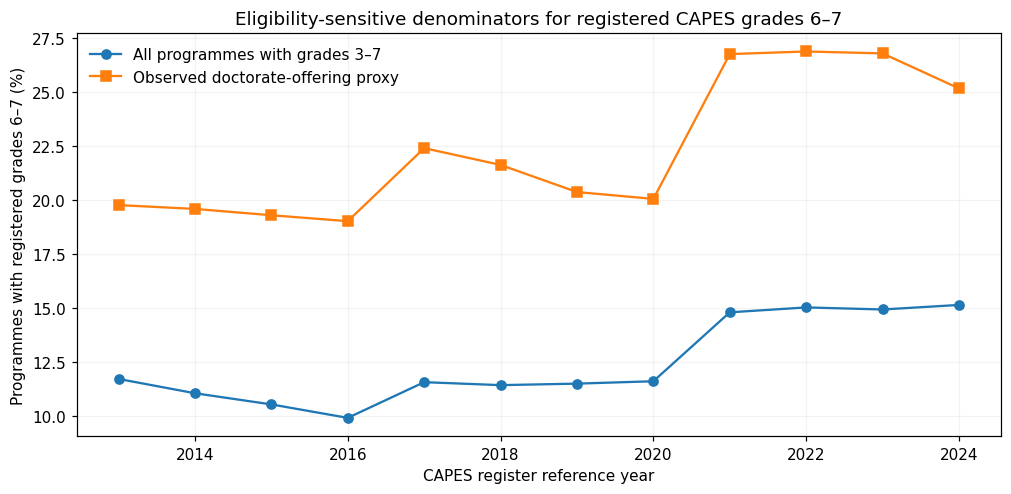


Figure 2. Changes in registered CAPES grade values between adjacent annual records
Note. Bars show changes in registry values for programme codes observed in both years; they do not date evaluation events or establish evaluation-causal effects.


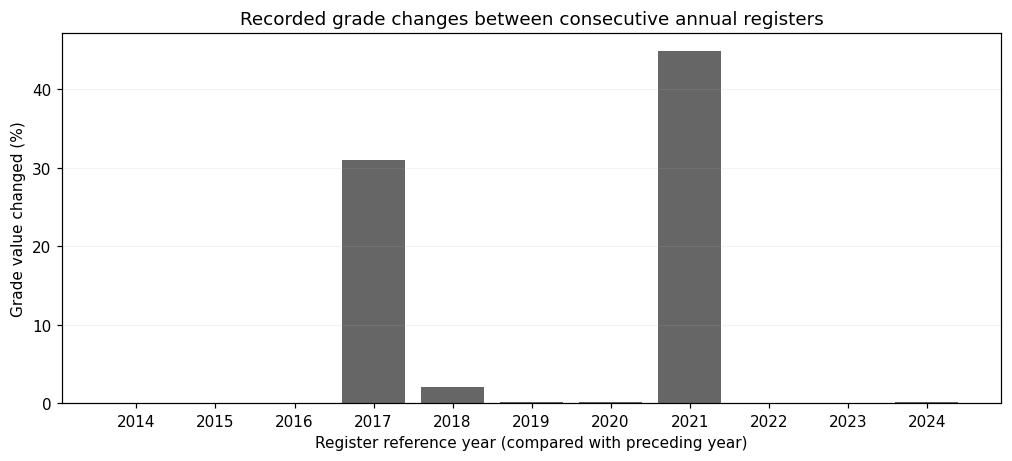


Figure 3. Gini coefficients using full-register and matched-only programme frames
Note. Unmatched records have unknown true production; they are coded zero only in the full-frame observed-count definition. Neither curve measures verified total doctoral completions.


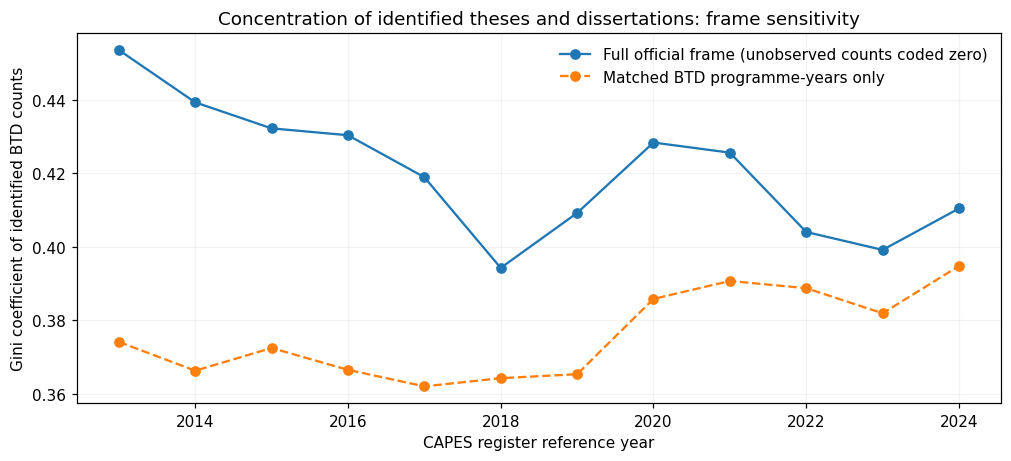


Figure 4. Lorenz curves of identified BTD counts in 2013 and 2024
Note. Full-register and matched-only frames are displayed separately; programme-years without identified records are not assumed to have zero true output.


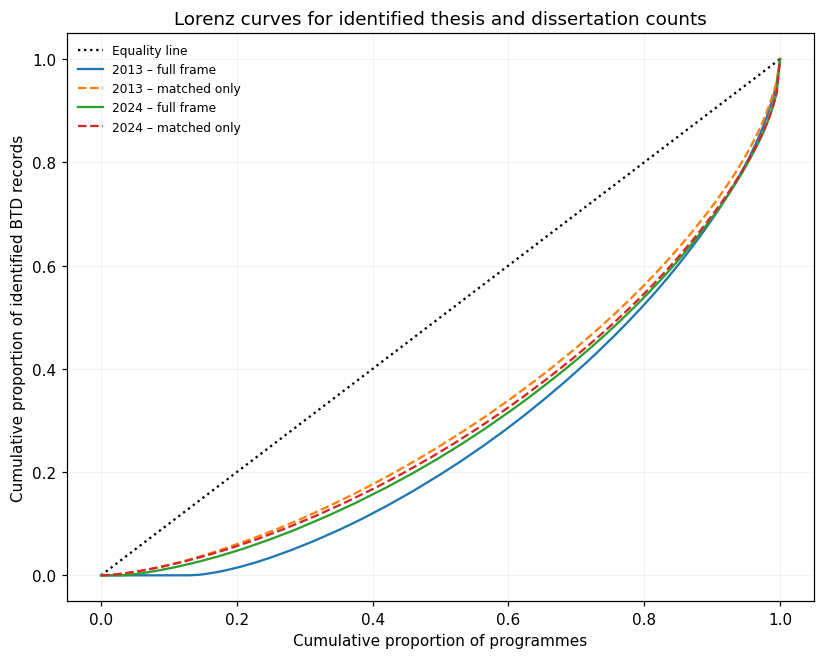


Figure 5. Within- and between-group contributions to BTD concentration
Note. Decompositions use the observed BTD counts in the full official programme-year frame; zeros indicate unobserved BTD records, not confirmed lack of output.


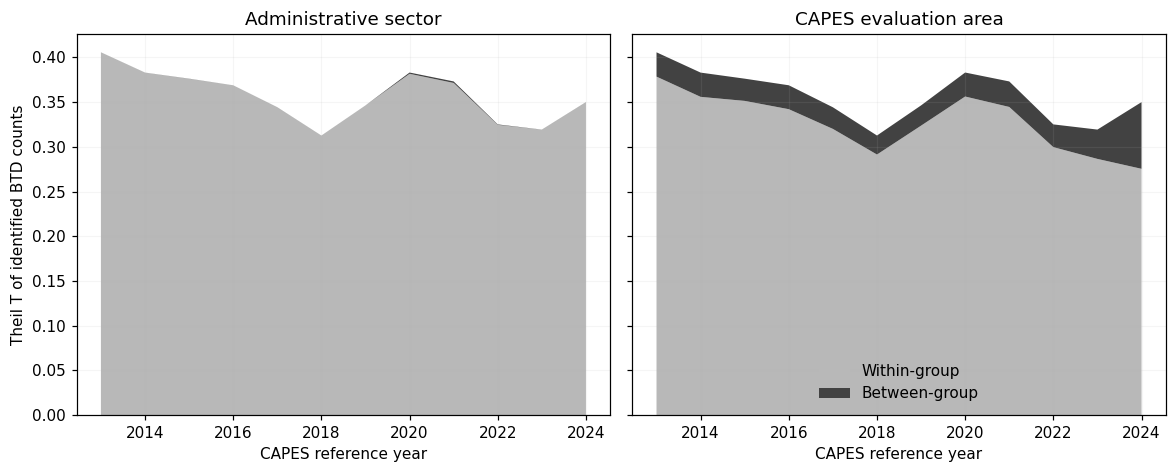


Figure 6. Data linkage and analytical population
Note. The official programme census is broader than the programme-years with identified BTD records. The flow does not claim complete detection of all dissertations.


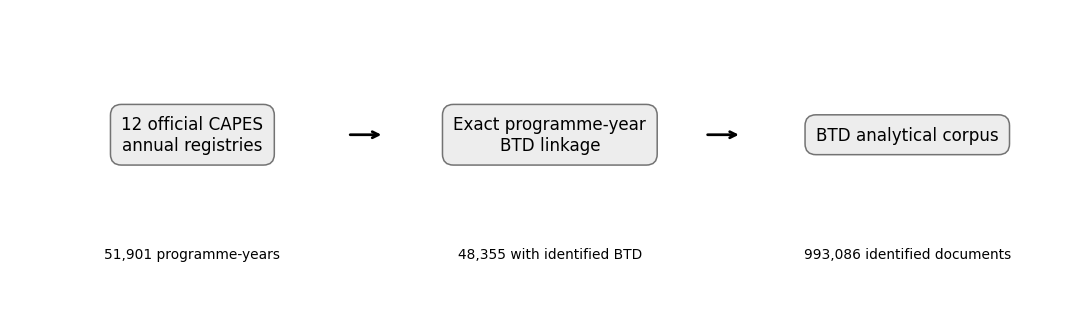


Table 1 Annual Eligibility | 12 rows


,year,Registered programmes,Numeric grades 3–7,Grades 6–7,"Share, numeric grades 3–7",Doctorate-offering proxy (numeric grades),Grades 6–7 among doctoral proxy,"Share, doctorate-offering proxy",Grade A,Proxy denominator including A-as-5,"Share, proxy plus A-as-5",Proxy coverage of all registered,Doctoral offering unknown,BTD documents identified
0,2013,3568.0,3537.0,415.0,0.117331,2100.0,415.0,0.197619,0.0,2100.0,0.197619,0.588565,0.0,67431.0
1,2014,3765.0,3748.0,415.0,0.110726,2119.0,415.0,0.195847,0.0,2119.0,0.195847,0.562815,0.0,70487.0
2,2015,3946.0,3931.0,415.0,0.105571,2151.0,415.0,0.192934,0.0,2151.0,0.192934,0.545109,0.0,75666.0
3,2016,4186.0,4177.0,415.0,0.099354,2182.0,415.0,0.190192,0.0,2182.0,0.190192,0.521261,0.0,80075.0
4,2017,4347.0,4299.0,498.0,0.115841,2224.0,498.0,0.223921,0.0,2224.0,0.223921,0.511617,0.0,85137.0
5,2018,4363.0,4298.0,492.0,0.114472,2276.0,492.0,0.216169,2.0,2276.0,0.216169,0.521659,0.0,90295.0
6,2019,4570.0,4272.0,492.0,0.115169,2416.0,492.0,0.203642,257.0,2434.0,0.202136,0.528665,0.0,94349.0
7,2020,4559.0,4223.0,491.0,0.116268,2449.0,491.0,0.200490,318.0,2476.0,0.198304,0.537179,0.0,79989.0
8,2021,4709.0,4551.0,674.0,0.148099,2521.0,674.0,0.267354,75.0,2528.0,0.266614,0.535358,0.0,82600.0
9,2022,4594.0,4476.0,673.0,0.150357,2506.0,673.0,0.268555,82.0,2512.0,0.267914,0.545494,0.0,83981.0



Table 2 Eligibility By Sector | 24 rows


,year,sector,Registered programmes,Numeric grades 3–7,Grades 6–7,"Share, numeric grades 3–7",Doctorate-offering proxy (numeric grades),Grades 6–7 among doctoral proxy,"Share, doctorate-offering proxy",Grade A,Proxy denominator including A-as-5,"Share, proxy plus A-as-5",Proxy coverage of all registered,Doctoral offering unknown,BTD documents identified
0,2013,Private,653.0,634.0,35.0,0.055205,308.0,35.0,0.113636,0.0,308.0,0.113636,0.471669,0.0,12073.0
1,2013,Public,2915.0,2903.0,380.0,0.130899,1792.0,380.0,0.212054,0.0,1792.0,0.212054,0.614751,0.0,55358.0
2,2014,Private,690.0,679.0,35.0,0.051546,313.0,35.0,0.111821,0.0,313.0,0.111821,0.453623,0.0,12629.0
3,2014,Public,3075.0,3069.0,380.0,0.123819,1806.0,380.0,0.210410,0.0,1806.0,0.210410,0.587317,0.0,57858.0
4,2015,Private,723.0,714.0,35.0,0.049020,322.0,35.0,0.108696,0.0,322.0,0.108696,0.445367,0.0,14343.0
5,2015,Public,3223.0,3217.0,380.0,0.118122,1829.0,380.0,0.207764,0.0,1829.0,0.207764,0.567484,0.0,61323.0
6,2016,Private,780.0,775.0,35.0,0.045161,334.0,35.0,0.104790,0.0,334.0,0.104790,0.428205,0.0,15055.0
7,2016,Public,3406.0,3402.0,380.0,0.111699,1848.0,380.0,0.205628,0.0,1848.0,0.205628,0.542572,0.0,65020.0
8,2017,Private,802.0,793.0,44.0,0.055485,348.0,44.0,0.126437,0.0,348.0,0.126437,0.433915,0.0,16232.0
9,2017,Public,3545.0,3506.0,454.0,0.129492,1876.0,454.0,0.242004,0.0,1876.0,0.242004,0.529196,0.0,68905.0



Table 3 Eligibility By Modality | 24 rows


...


Table 9 Institution Cluster Robust Models | 3 rows


,year,n_initial,n_retained,fraction_retained,n_areas,cluster_unit,n_clusters,log_OR_public,cluster_SE,OR_public_vs_private,CI95_low,CI95_high,p_value_model,deviance,Brier_score_descriptive,model_scope
0,2016,3474,1623,0.467185,17,CAPES institution code,280,0.158833,0.511156,1.172142,0.430403,3.192167,0.756004,1006.751955,0.087620,Academic programmes; V2 strict common area sup...
1,2020,3498,1758,0.502573,20,CAPES institution code,292,0.103267,0.386863,1.108788,0.519450,2.366752,0.789519,1195.199670,0.097171,Academic programmes; V2 strict common area sup...
2,2024,3658,2387,0.652542,27,CAPES institution code,325,-0.021777,0.372626,0.978458,0.471365,2.031084,0.953397,2055.077620,0.132635,Academic programmes; V2 strict common area sup...



Supplement S6 Threshold Sensitivity | 12 rows


,year,threshold,sector,n_doctoral_academic,n_threshold,share
0,2016,Grades ≥5,Private,334,114,0.341317
1,2016,Grades ≥5,Public,1848,879,0.475649
2,2016,Grades 6–7,Private,334,35,0.104790
3,2016,Grades 6–7,Public,1848,380,0.205628
4,2020,Grades ≥5,Private,389,163,0.419023
5,2020,Grades ≥5,Public,2019,1037,0.513621
6,2020,Grades 6–7,Private,389,44,0.113111
7,2020,Grades 6–7,Public,2019,447,0.221397
8,2024,Grades ≥5,Private,405,221,0.545679
9,2024,Grades ≥5,Public,2177,1388,0.637575



FINAL REVIEW — ALL TABLES AND FIGURES PRINTED IN ENGLISH
{
  "generated_utc": "2026-10-23T19:45:50.675351+00:00",
  "status": "INTEGRATED_REVIEW_ANALYSES_COMPLETED_CONDITIONAL_INTERPRETATION",
  "n_official_ppg_year": 51901,
  "n_identified_btd": 993086,
  "n_ppg_year_with_btd": 48355,
  "n_doctorate_proxy_known": 51901,
  "high_grades_without_confirmed_doctorate_proxy": 0,
  "scope": "CAPES official census 2013–2024, identified BTD only",
  "embeddings_used": false,
  "new_downloads": false,
  "causal_claims": false,
  "grade_6_7_formal_eligibility": "NOT_ESTABLISHED; OBSERVED DEGREE PROXY ONLY",
  "regressions": 3,
  "table_count": 17,
  "figure_count": 6,
  "runtime_versions": {
    "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
    "pandas": "2.2.3",
    "numpy": "2.1.3",
    "statsmodels": "0.15.0",
    "scipy": "1.16.3",
    "matplotlib": "3.10.0"
  },
  "original_census_sha256": "a566c9a756599e62c060b43fb95a1b6f6d273046bd9969f9ec9d4b6e9a775a08"
}
OUTPUT: /conte

In [4]:
# CELL 4/4 — CPU | ENGLISH JOURNAL TABLES, PRINTED FIGURES, DATA DICTIONARY AND MANIFEST
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from importlib.metadata import version
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'figure.dpi':110})
figures=[]
def publish_figure(filename,fig,title,note):
    fig.tight_layout()
    fig.savefig(FIG/f'{filename}.png',dpi=320,bbox_inches='tight')
    fig.savefig(FIG/f'{filename}.pdf',bbox_inches='tight')
    figures.append({'filename':filename,'title':title,'note':note})
    print(f'\n{title}\nNote. {note}')
    display(fig)
    plt.close(fig)

# FIG 1: Eligibility sensitivity — observed doctorate proxy vs grades 3–7, annual reference year.
a=T['Table_1_Annual_Eligibility']
fig,ax=plt.subplots(figsize=(9.3,4.6))
ax.plot(a.year,100*a['Share, numeric grades 3–7'],marker='o',label='All programmes with grades 3–7')
ax.plot(a.year,100*a['Share, doctorate-offering proxy'],marker='s',label='Observed doctorate-offering proxy')
ax.set(xlabel='CAPES register reference year',ylabel='Programmes with registered grades 6–7 (%)',
 title='Eligibility-sensitive denominators for registered CAPES grades 6–7')
ax.legend(frameon=False);ax.grid(alpha=.15)
publish_figure('Figure_1_Eligible_Denominators',fig,'Figure 1. High-grade proportions under alternative observed denominators, 2013–2024',
 'The doctorate-offering group is a necessary-condition proxy and does not establish full regulatory eligibility. Register reference years are not evaluation-event years.')
# FIG 2: grouped registry value transitions
z=T['Supplement_S3_Registry_Grade_Change_Audit']
fig,ax=plt.subplots(figsize=(9.3,4.3))
ax.bar(z.year,100*z.Share_changed,color='.40');ax.set_xticks(list(range(2014,2025)))
ax.set(xlabel='Register reference year (compared with preceding year)',ylabel='Grade value changed (%)',
 title='Recorded grade changes between consecutive annual registers')
ax.grid(axis='y',alpha=.15)
publish_figure('Figure_2_Registered_Grade_Updates',fig,'Figure 2. Changes in registered CAPES grade values between adjacent annual records',
 'Bars show changes in registry values for programme codes observed in both years; they do not date evaluation events or establish evaluation-causal effects.')
# FIG 3: BTD matched-only vs full-frame sensitivity
fig,ax=plt.subplots(figsize=(9.3,4.3))
for frame,label,sty in [('FULL_FRAME_UNOBSERVED_AS_ZERO','Full official frame (unobserved counts coded zero)','-'),
                        ('MATCHED_ONLY','Matched BTD programme-years only','--')]:
    z=M[M.frame.eq(frame)];ax.plot(z.year,z.Gini,linestyle=sty,marker='o',label=label)
ax.set(title='Concentration of identified theses and dissertations: frame sensitivity',
 xlabel='CAPES register reference year',ylabel='Gini coefficient of identified BTD counts');ax.grid(alpha=.15);ax.legend(frameon=False)
publish_figure('Figure_3_Gini_Frame_Sensitivity',fig,'Figure 3. Gini coefficients using full-register and matched-only programme frames',
 'Unmatched records have unknown true production; they are coded zero only in the full-frame observed-count definition. Neither curve measures verified total doctoral completions.')
# FIG 4: Lorenz anchor years, full frame vs matched
fig,ax=plt.subplots(figsize=(7.6,6.1));ax.plot([0,1],[0,1],linestyle=':',color='black',label='Equality line')
for yr in [2013,2024]:
    for frame in ['FULL_FRAME_UNOBSERVED_AS_ZERO','MATCHED_ONLY']:
        z=L[L.year.eq(yr)&L.frame.eq(frame)]
        ax.plot(z.Programme_population_share,z.BTD_output_share,
                linestyle='-' if frame=='FULL_FRAME_UNOBSERVED_AS_ZERO' else '--',
                label=f'{yr} – '+('full frame' if frame=='FULL_FRAME_UNOBSERVED_AS_ZERO' else 'matched only'))
ax.set(title='Lorenz curves for identified thesis and dissertation counts',xlabel='Cumulative proportion of programmes',
 ylabel='Cumulative proportion of identified BTD records');ax.legend(fontsize=8,frameon=False);ax.grid(alpha=.15)
publish_figure('Figure_4_Lorenz_Anchor_Years',fig,'Figure 4. Lorenz curves of identified BTD counts in 2013 and 2024',
 'Full-register and matched-only frames are displayed separately; programme-years without identified records are not assumed to have zero true output.')
# FIG 5: Theil within/between area and administration
fig,axes=plt.subplots(1,2,figsize=(10.8,4.4),sharey=True)
for ax,grp,name in zip(axes,['sector','area'],['Administrative sector','CAPES evaluation area']):
    z=TB[TB.grouping.eq(grp)].sort_values('year')
    ax.stackplot(z.year,z.Theil_T_within,z.Theil_T_between,labels=['Within-group','Between-group'],colors=['.72','.26'])
    ax.set(title=name,xlabel='CAPES reference year');ax.grid(alpha=.12)
axes[0].set_ylabel('Theil T of identified BTD counts');axes[1].legend(frameon=False)
publish_figure('Figure_5_Theil_Decomposition',fig,'Figure 5. Within- and between-group contributions to BTD concentration',
 'Decompositions use the observed BTD counts in the full official programme-year frame; zeros indicate unobserved BTD records, not confirmed lack of output.')
# FIG 6 data flow: transparent actual counts
fig,ax=plt.subplots(figsize=(10,3));ax.axis('off')
steps=[('12 official CAPES\nannual registries','51,901 programme-years'),('Exact programme-year\nBTD linkage','48,355 with identified BTD'),('BTD analytical corpus','993,086 identified documents')]
for i,(main,small) in enumerate(steps):
    x=.03+i*.335
    ax.text(x+.14,.58,main,ha='center',va='center',fontsize=11,
            bbox={'boxstyle':'round,pad=.65','facecolor':'.93','edgecolor':'.45'})
    ax.text(x+.14,.18,small,ha='center',va='center',fontsize=9)
    if i<2:ax.annotate('',xy=(x+.32,.58),xytext=(x+.285,.58),arrowprops={'arrowstyle':'->','lw':1.8})
publish_figure('Figure_6_Data_Flow',fig,'Figure 6. Data linkage and analytical population',
 'The official programme census is broader than the programme-years with identified BTD records. The flow does not claim complete detection of all dissertations.')

# Print ALL output tables on the Colab screen using friendly titles; do not truncate silently.
for name,df in T.items():
    print('\n'+'='*100+'\n'+name.replace('_',' ')+' | '+str(len(df))+' rows\n'+'='*100)
    with pd.option_context('display.max_rows',min(1000,len(df)),'display.max_columns',None,'display.width',230):
        display(df)
# Avoid dumping 50k rows; source panel is provided as parquet and codebook.
with pd.ExcelWriter(OUT/'FINAL_QHE_TABLES_ENGLISH.xlsx',engine='openpyxl') as xls:
    for name,df in T.items():
        short=name[:31]
        df.to_excel(xls,sheet_name=short,index=False)
# Definition dictionary and scientific flags
codebook=[
 ('ppg','Official CAPES programme identifier','Identifier','No direct institution resolution for multi-institution arrangements'),
 ('year','CAPES register reference year','Year','Not an evaluation-event year'),
 ('grade_label','Registered CAPES grade (1–7, A or other)','Categorical','A retained; A-as-5 is sensitivity only'),
 ('degree_raw','Registered NM_GRAU_PROGRAMA','Categorical','Degree field only; no verification of effective doctorate functioning'),
 ('doctoral_observed','Doctorate mentioned in degree field','Boolean with missing','Necessary-condition proxy, not complete grade 6–7 eligibility'),
 ('eligible_proxy','Doctorate observed and registered numeric grade 3–7','Boolean','Not legally complete eligibility; does not apply minimum doctoral-age or current-cycle excellence requirements'),
 ('high_grade','Registered grade 6 or 7','Boolean','Observed grade, not annual award event'),
 ('sector','Registered dependency: Public/Private','Categorical','Sector is not a resource measure'),
 ('programme_modality','Academic/Professional','Categorical','Programme type is not quality category'),
 ('area','CAPES evaluation area code','Categorical','Discipline-adjusted common support may select subpopulation'),
 ('age_observed','Reference year minus official programme start year','Years or missing','Programme age is not doctorate-course age'),
 ('has_btd_record','Programme-year with ≥1 identified thesis/dissertation','Boolean','Absence of linkage is not confirmed zero output'),
 ('n_docs','Number of identified BTD records','Nonnegative count','Only identified theses/dissertations, not all scientific publications'),
 ('Theil_T','Generalised entropy index GE(1)','Index','Zero observed counts are permitted; within/between add exactly'),
 ('Theil_L','Mean log deviation GE(0)','Index','Infinite when true input includes observed zeros; never silently regularised')]
book=pd.DataFrame(codebook,columns=['Variable','Definition','Scale','Interpretation and limitations'])
book.to_csv(OUT/'FINAL_DATA_DICTIONARY_EN.csv',index=False,encoding='utf-8-sig')
limitations=[
 'Grade 6–7 full eligibility cannot be established from degree labels alone. Doctoral-course start, cycle-specific performance and area-level rules remain unavailable.',
 'The A grade has been retained separately. As-if-5 denominator sensitivity is not an asserted universal historical equivalence.',
 'Grouping years into 2013–2016, 2017–2020 and 2021–2024 is descriptive; it does not align grades to confirmed result-publication dates.',
 'Unmatched BTD years are unobserved production. Full-frame and matched-only indices are sensitivity scenarios, not identified bounds for true production.',
 'Clustered associative regressions depend on V2 strict common-support selection; do not extrapolate to excluded programmes.',
 'No valid probabilistic completeness rate for BTD documents can be inferred from exact programme-year linkage alone.',
 'No models address causal effects, and the official programme registry is a census rather than a random sample.',
 'No programme-specific external evaluation rules were automatically inferred from administrative values.'
]
(outfile:=OUT/'FINAL_METHODS_AND_LIMITATIONS_EN.md').write_text(
 '# Integrated CAPES 2013–2024 reviewer-response analytical revision\n\n'
 '## Main question\nHow do registered grades, programme eligibility proxies, national registry composition and observed training-document concentration differ across Brazilian postgraduate programmes?\n\n'
 '## Design\nFull annual official CAPES register, descriptive comparisons, cohort-style repeated observations, symmetric Kitagawa decomposition, observed-coverage frame sensitivity, decomposable Theil T, and noncausal clustered logistic models on V2 strict within-area support.\n\n'
 '## Important limitations\n'+''.join('- '+x+'\n' for x in limitations)+'\n'
 '## Source documentation\n- CAPES evaluation FAQ: https://www.gov.br/capes/pt-br/acesso-a-informacao/perguntas-frequentes/avaliacao-da-pos-graduacao\n'
 '- CAPES guidance on eligibility (2025, later cycle): https://uploads.capes.gov.br/files/2025-05-02_DocumentoReferencial_FICHA.pdf\n'
 '- CAPES 2021–2024 results announced in 2026: https://www.gov.br/capes/pt-br/acesso-a-informacao/acoes-e-programas/avaliacao/avaliacao-quadrienal/resultado-da-avaliacao-quadrienal-2021-2024\n'
 '\nThese sources provide interpretive context, not an automatically assigned eligibility label for every 2013–2024 programme.\n',encoding='utf-8')
# Freeze this execution's outputs and record versions/checksums.
files=sorted([p for p in OUT.rglob('*') if p.is_file() and p.name!='FINAL_MANIFEST.json'])
manifest={'generated_utc':datetime.now(timezone.utc).isoformat(),
 'status':'INTEGRATED_REVIEW_ANALYSES_COMPLETED_CONDITIONAL_INTERPRETATION',
 'n_official_ppg_year':len(c),'n_identified_btd':int(c.n_docs.sum()),
 'n_ppg_year_with_btd':int(c.has_btd_record.sum()),
 'n_doctorate_proxy_known':int(c.doctoral_observed.notna().sum()),
 'high_grades_without_confirmed_doctorate_proxy':int(len(anomalies)),
 'scope':'CAPES official census 2013–2024, identified BTD only',
 'embeddings_used':False,'new_downloads':False,'causal_claims':False,
 'grade_6_7_formal_eligibility':'NOT_ESTABLISHED; OBSERVED DEGREE PROXY ONLY',
 'regressions':len(REG),'table_count':len(T),'figure_count':len(figures),
 'runtime_versions':{'python':sys.version,'pandas':pd.__version__,'numpy':np.__version__,
                     'statsmodels':version('statsmodels'),'scipy':version('scipy'),
                     'matplotlib':version('matplotlib')},
 'original_census_sha256':file_sha(SOURCES['census']),
 'files':[{'path':str(p.relative_to(OUT)),'sha256':file_sha(p),'bytes':p.stat().st_size} for p in files]}
(OUT/'FINAL_MANIFEST.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
print('\n'+'='*100+'\nFINAL REVIEW — ALL TABLES AND FIGURES PRINTED IN ENGLISH\n'+'='*100)
print(json.dumps({k:v for k,v in manifest.items() if k!='files'},indent=2,ensure_ascii=False,default=str))
print('OUTPUT:',OUT)
